# PI7 Part 1 — European Map Colouring: Basic GA and HCA

This notebook compares two approaches to four-colour the country-border graph:

1. **Basic GA**, using two-best parent selection, one-point crossover, conflict-directed valid-colour mutation, and elitist survivor selection.
2. **Galinier–Hao HCA (1999):** GPX recombination, tabu-search improvement, and replacement of the worse selected parent.

The basic GA uses conflict-directed valid-colour mutation inspired by Hindi and Yampolskiy (2012); it is a focused adaptation of that operator, not a reproduction of their full hybrid method. Fitness is the number of conflicting borders; zero is a legal four-colouring. HCA is a hybrid evolutionary extension, not a standard GA.

**Graph model:** 46 listed countries/territories and 89 deduplicated land borders. Iceland and Cyprus are isolated vertices; Kosovo is modelled as a separate vertex. Discuss the manually specified graph scope in the report.

The notebook contains implementation, parameter experiments, comparison plots, and inline maps. Also prepare the required research/evaluation report and maximum 15-minute video.


## 1. Europe graph data

Each land border is an undirected edge. Iceland and Cyprus remain isolated vertices; Kosovo is represented as a separate vertex. The country ordering defines the chromosome gene ordering and is kept fixed.


In [ ]:
import random
import time

# The gene at index i corresponds to countries[i]. Keep this order fixed.
countries = [
    "Albania", "Andorra", "Austria", "Belarus", "Belgium",
    "Bosnia and Herzegovina", "Bulgaria", "Croatia", "Cyprus", "Czechia",
    "Denmark", "Estonia", "Finland", "France", "Germany", "Greece",
    "Hungary", "Iceland", "Ireland", "Italy", "Kosovo", "Latvia", "Liechtenstein", "Lithuania",
    "Luxembourg", "Moldova", "Monaco", "Montenegro", "Netherlands",
    "North Macedonia", "Norway", "Poland", "Portugal", "Romania", "Russia",
    "San Marino", "Serbia", "Slovakia", "Slovenia", "Spain", "Sweden",
    "Switzerland", "Turkey", "Ukraine", "United Kingdom", "Vatican City",
]

# Each tuple is one shared land border. Isolated territories remain vertices but add no conflicts.
borders = [
    ("Albania", "Greece"), ("Albania", "Montenegro"), ("Albania", "North Macedonia"),
    ("Andorra", "France"), ("Andorra", "Spain"),
    ("Austria", "Czechia"), ("Austria", "Germany"), ("Austria", "Hungary"),
    ("Austria", "Italy"), ("Austria", "Liechtenstein"), ("Austria", "Slovakia"),
    ("Austria", "Slovenia"), ("Austria", "Switzerland"),
    ("Belarus", "Latvia"), ("Belarus", "Lithuania"), ("Belarus", "Poland"),
    ("Belarus", "Russia"), ("Belarus", "Ukraine"),
    ("Belgium", "France"), ("Belgium", "Germany"), ("Belgium", "Luxembourg"),
    ("Belgium", "Netherlands"),
    ("Bosnia and Herzegovina", "Croatia"), ("Bosnia and Herzegovina", "Montenegro"),
    ("Bosnia and Herzegovina", "Serbia"),
    ("Bulgaria", "Greece"), ("Bulgaria", "North Macedonia"), ("Bulgaria", "Romania"),
    ("Bulgaria", "Serbia"), ("Bulgaria", "Turkey"),
    ("Croatia", "Hungary"), ("Croatia", "Montenegro"), ("Croatia", "Serbia"),
    ("Croatia", "Slovenia"),
    ("Czechia", "Germany"), ("Czechia", "Poland"), ("Czechia", "Slovakia"),
    ("Denmark", "Germany"),
    ("Estonia", "Latvia"), ("Estonia", "Russia"),
    ("Finland", "Norway"), ("Finland", "Russia"), ("Finland", "Sweden"),
    ("France", "Germany"), ("France", "Italy"), ("France", "Luxembourg"),
    ("France", "Monaco"), ("France", "Spain"), ("France", "Switzerland"),
    ("Germany", "Luxembourg"), ("Germany", "Netherlands"), ("Germany", "Poland"),
    ("Germany", "Switzerland"),
    ("Greece", "North Macedonia"), ("Greece", "Turkey"),
    ("Hungary", "Romania"), ("Hungary", "Serbia"), ("Hungary", "Slovakia"),
    ("Hungary", "Slovenia"), ("Hungary", "Ukraine"),
    ("Ireland", "United Kingdom"),
    ("Kosovo", "Albania"), ("Kosovo", "Montenegro"),
    ("Kosovo", "North Macedonia"), ("Kosovo", "Serbia"),
    ("Italy", "San Marino"), ("Italy", "Slovenia"), ("Italy", "Switzerland"),
    ("Italy", "Vatican City"),
    ("Latvia", "Lithuania"), ("Latvia", "Russia"),
    ("Liechtenstein", "Switzerland"),
    ("Lithuania", "Poland"), ("Lithuania", "Russia"),
    ("Luxembourg", "Germany"), ("Luxembourg", "France"),
    ("Moldova", "Romania"), ("Moldova", "Ukraine"),
    ("Montenegro", "Serbia"),
    ("Netherlands", "Belgium"),
    ("North Macedonia", "Serbia"),
    ("Norway", "Russia"), ("Norway", "Sweden"),
    ("Poland", "Russia"), ("Poland", "Slovakia"), ("Poland", "Ukraine"),
    ("Portugal", "Spain"),
    ("Romania", "Serbia"), ("Romania", "Ukraine"),
    ("Russia", "Ukraine"),
    ("Serbia", "Romania"), ("Serbia", "Hungary"),
    ("Slovakia", "Ukraine"),
    ("Slovenia", "Italy"), ("Slovenia", "Austria"),
    ("Spain", "United Kingdom"),
    ("Sweden", "Norway"),
    ("Switzerland", "Italy"), ("Switzerland", "France"),
    ("Turkey", "Greece"), ("Turkey", "Bulgaria"),
]

country_to_index = {country: index for index, country in enumerate(countries)}
assert len(country_to_index) == len(countries), "Country names must be unique."
assert all(country in country_to_index for border in borders for country in border)

adjacency = {country: set() for country in countries}
for first_country, second_country in borders:
    adjacency[first_country].add(second_country)
    adjacency[second_country].add(first_country)

# Convert sets to sorted lists to make experiments reproducible and readable.
adjacency = {country: sorted(neighbours) for country, neighbours in adjacency.items()}

print(f"Countries: {len(countries)}")
print(f"Border edges: {len(borders)}")
print(f"Countries with at least one border: {len(adjacency)}")

Countries: 46
Border edges: 101
Countries with at least one border: 46


In [12]:
# Normalise the graph as an undirected simple graph before evaluating fitness.
borders = sorted({tuple(sorted(border)) for border in borders})

adjacency = {country: set() for country in countries}
for first_country, second_country in borders:
    adjacency[first_country].add(second_country)
    adjacency[second_country].add(first_country)
adjacency = {country: sorted(neighbours) for country, neighbours in adjacency.items()}

assert all(first in countries and second in countries for first, second in borders)
assert all(second in adjacency[first] and first in adjacency[second] for first, second in borders)
assert len(borders) == sum(len(neighbours) for neighbours in adjacency.values()) // 2

print(f"Normalised border edges: {len(borders)}")
print("Example neighbours of Germany:", adjacency["Germany"])
print("Graph validation passed.")

Normalised border edges: 89
Example neighbours of Germany: ['Austria', 'Belgium', 'Czechia', 'Denmark', 'France', 'Luxembourg', 'Netherlands', 'Poland', 'Switzerland']
Graph validation passed.


## 2. Basic GA design

| Component | Implemented method | Rationale and trade-off |
|---|---|---|
| Representation | Integer vector, one colour per country | Direct representation; colour labels are interchangeable. |
| Fitness | Number of conflicting borders, minimized to zero | Direct measure of violations. |
| Parent selection | Select the two current individuals with lowest conflict counts | Simple and exploitative, but repeatedly using the same parents can reduce diversity. |
| Recombination | One-point crossover; repeat to create a full offspring population | Simple; the fixed country order is not geographic, so the cut may divide useful groups. |
| Mutation | For each conflicting country, mutate with probability `p_m` to a colour unused by its neighbours, if one exists | Targets actual conflicts and avoids introducing a local conflict where a valid colour is available; it can leave conflicts unchanged when no colour is available. |
| Survivor selection | Keep the best `N` candidates from parents plus offspring | Elitist and preserves strong candidates, but can increase selection pressure. |

Conflict-directed valid-colour mutation is adapted from the `mutation1` operator described by Hindi and Yampolskiy (2012). The implementation retains the two-best parent selection and elitist survival used in this notebook; it does not reproduce the paper's adaptive switching, mutation2, or wisdom-of-crowds stage. We tune population size and the per-conflicting-country mutation probability.

### Theoretical alternatives and trade-offs

| Component | Selected | Alternative | Comparison |
|---|---|---|---|
| Representation | Integer colour vector | Partition/colour-class encoding | Integer vectors are compact and direct; partitions remove colour-label symmetry and support graph-aware crossover but require more complex operators. HCA uses groups for GPX while retaining vectors as storage. |
| Parent selection | Two-best truncation | Tournament, roulette-wheel, rank selection | Truncation is simple and exploitative, but can collapse diversity; tournament controls pressure, roulette uses fitness-proportionate chances, and rank selection is less sensitive to raw fitness scaling. |
| Recombination | One-point (basic GA); GPX (HCA) | Uniform assignment crossover | One-point is simple but gene order is arbitrary. Uniform crossover mixes genes more broadly but can disrupt useful sets. GPX preserves graph-colouring groups at added complexity. |
| Mutation / improvement | Conflict-directed valid-colour repair (basic GA); tabu search (HCA) | Conflict-directed random colour | Valid-colour repair targets conflicted countries and avoids neighbour colours when possible. Tabu search performs guided local moves, costs more computation, and is not ordinary GA mutation. |
| Survivor selection | Best `N` from parents+offspring (basic GA); replace worse selected parent (HCA) | Generational replacement; random refill | Elitism preserves strong candidates but may increase selection pressure; random refill explores more but can discard good solutions; HCA performs local parent replacement. |

The table compares selected methods with theoretical alternatives; it does not claim they outperform every alternative experimentally.

### HCA: Galinier and Hao (1999)
HCA views a colouring as a partition into colour classes. GPX alternates between two parents and transfers their largest remaining classes into the child; tabu search then improves the child by recolouring conflicting countries while temporarily forbidding reversals. The child replaces the worse of its two selected parents. HCA does not use ordinary per-gene mutation: tabu search is local improvement, not mutation.

Galinier and Hao motivate partition crossover as transmitting meaningful groups rather than arbitrary vertex-colour assignments and report that partition crossovers can outperform assignment crossovers in their hybrid setting. Their results concern the combined HCA and benchmark graphs, not a proof that HCA always outperforms this basic GA on Europe.

### Research sources

- ZM002 course example, `ai_dc3_genetic_algorithm.ipynb`, supplied in `part1/examples/`. It provides background on a general GA pattern; this notebook instead uses a graph-colouring-specific mutation operator.
- Hindi, M. M., & Yampolskiy, R. V. *Genetic Algorithm Applied to the Graph Coloring Problem*. Supplied article PDF. The basic GA adapts its conflict-directed valid-colour mutation operator; its adaptive switching and wisdom-of-crowds stages are not implemented.
- Galinier, P., & Hao, J.-K. (1999). “Hybrid Evolutionary Algorithms for Graph Coloring.” *Journal of Combinatorial Optimization*, 3, 379–397. https://doi.org/10.1023/A:1009823419804.
- Porumbel, D. C., Hao, J.-K., & Kuntz, P. (2010). “An evolutionary approach with diversity guarantee and well-informed grouping recombination for graph coloring.” *Computers & Operations Research*, 37, 1822–1832. https://doi.org/10.1016/j.cor.2010.01.015. Background on later graph-colouring evolutionary design; not implemented in this notebook.


## 3. Shared fitness and HCA tabu search

`count_conflicts` counts each undirected border edge once. HCA uses a Tabucol-style local search: consider recolourings for countries currently in conflict, choose a best permitted move, and temporarily mark its reversal tabu. Aspiration allows a tabu move when it improves the best-known solution. The move budget is capped per offspring.


In [13]:
import math
import random
import time
from statistics import mean, median

num_colours = 4
indexed_borders = [
    (country_to_index[first], country_to_index[second]) for first, second in borders
]
indexed_neighbours = [
    [country_to_index[neighbour] for neighbour in adjacency[country]]
    for country in countries
]


def count_conflicts(individual):
    return sum(individual[first] == individual[second] for first, second in indexed_borders)


def random_colouring(rng):
    return [rng.randrange(num_colours) for _ in countries]


def tabu_search(start, move_budget, rng, tenure_a=10, tenure_alpha=0.6):
    """Return best colouring, conflict count, and number of tabu moves executed."""
    current = start[:]
    current_conflicts = count_conflicts(current)
    best = current[:]
    best_conflicts = current_conflicts
    tabu_until = [[0] * num_colours for _ in countries]
    moves_used = 0

    for iteration in range(1, move_budget + 1):
        if current_conflicts == 0:
            break
        conflicting_vertices = {
            vertex
            for first, second in indexed_borders
            if current[first] == current[second]
            for vertex in (first, second)
        }
        candidates = []
        for vertex in conflicting_vertices:
            old_colour = current[vertex]
            for new_colour in range(num_colours):
                if new_colour == old_colour:
                    continue
                delta = sum(
                    (new_colour == current[neighbour]) - (old_colour == current[neighbour])
                    for neighbour in indexed_neighbours[vertex]
                )
                score = current_conflicts + delta
                if tabu_until[vertex][new_colour] < iteration or score < best_conflicts:
                    candidates.append((score, vertex, new_colour, old_colour))
        if not candidates:
            break
        best_score = min(candidate[0] for candidate in candidates)
        score, vertex, new_colour, old_colour = rng.choice(
            [candidate for candidate in candidates if candidate[0] == best_score]
        )
        current[vertex] = new_colour
        current_conflicts = score
        tenure = rng.randint(1, tenure_a) + int(tenure_alpha * len(conflicting_vertices))
        tabu_until[vertex][old_colour] = iteration + tenure
        moves_used = iteration
        if current_conflicts <= best_conflicts:
            best = current[:]
            best_conflicts = current_conflicts
    return best, best_conflicts, moves_used


assert len(countries) == 46
assert len(indexed_borders) == 89
assert count_conflicts([0] * len(countries)) == len(borders)
print(f"Validated graph: {len(countries)} countries, {len(borders)} unique borders.")


Validated graph: 46 countries, 89 unique borders.


## 4. Algorithm A — Basic GA with conflict-directed mutation

Each generation selects the two current individuals with the fewest conflicts, creates `population_size` one-point crossover offspring, and probabilistically recolours each child country involved in a conflict using a colour not used by its neighbours when available. It then keeps the best `population_size` candidates from parents plus offspring. The mutation operator is adapted from Hindi and Yampolskiy (2012); parent selection and survivor selection remain the simple two-best and elitist methods described above.

### Pseudocode for Basic GA

```text
Create a population of random colourings
Remember the best colouring so far

Repeat until a legal colouring is found or the epoch limit is reached:
    Count conflicts across all borders for each whole colouring
    Choose the two whole colourings with the lowest total conflict counts
    Make population_size children:
        Combine the parents with one-point crossover
        For each country involved in a conflict:
            With probability mutation_rate, choose a colour unused by its neighbours
            If no such colour exists, leave it unchanged
    From the old population and all children, keep the population_size
        colourings with the fewest conflicts
    Update the best-so-far colouring

Return the best colouring and its conflict count
```


In [14]:
def colour_classes(individual):
    return [
        {vertex for vertex, colour in enumerate(individual) if colour == colour_id}
        for colour_id in range(num_colours)
    ]


def gpx_crossover(first_parent, second_parent, rng):
    """Alternate parents and copy each turn's largest remaining colour class."""
    remaining = [set(range(len(countries))), set(range(len(countries)))]
    parent_classes = [colour_classes(first_parent), colour_classes(second_parent)]
    child = [-1] * len(countries)
    for child_colour in range(num_colours):
        parent_id = child_colour % 2
        candidates = [group & remaining[parent_id] for group in parent_classes[parent_id]]
        largest = max(map(len, candidates))
        selected = rng.choice([group for group in candidates if len(group) == largest])
        for vertex in selected:
            child[vertex] = child_colour
        for parent_remaining in remaining:
            parent_remaining.difference_update(selected)
    for vertex, colour in enumerate(child):
        if colour == -1:
            child[vertex] = rng.randrange(num_colours)
    return child


def mutate_conflicts_valid_colour(individual, mutation_rate, rng):
    """Probabilistically recolour conflicted countries with a neighbour-safe colour."""
    child = individual[:]
    conflicting_vertices = sorted({
        vertex
        for first, second in indexed_borders
        if child[first] == child[second]
        for vertex in (first, second)
    })
    rng.shuffle(conflicting_vertices)
    for vertex in conflicting_vertices:
        if rng.random() >= mutation_rate:
            continue
        used_by_neighbours = {child[neighbour] for neighbour in indexed_neighbours[vertex]}
        available_colours = [colour for colour in range(num_colours) if colour not in used_by_neighbours]
        if available_colours:
            child[vertex] = rng.choice(available_colours)
    return child


def select_two_best(population, rng=None):
    """Return copies of the two individuals with the lowest conflict counts."""
    ranked = sorted(population, key=count_conflicts)
    if len(ranked) < 2:
        raise ValueError("The GA needs at least two individuals for crossover.")
    return ranked[0][:], ranked[1][:]


def one_point_crossover(first_parent, second_parent, rng):
    """Create one child using one random cut between the two parents."""
    cut = rng.randint(1, len(first_parent) - 1)
    return first_parent[:cut] + second_parent[cut:]


def elitist_survivors(parents, offspring, population_size):
    """Keep the best population_size candidates from parents and offspring."""
    ranked = sorted(parents + offspring, key=count_conflicts)
    return [candidate[:] for candidate in ranked[:population_size]]


def run_basic_ga(config):
    """Run the basic GA with conflict-directed mutation and two-best selection."""
    rng = random.Random(config["seed"])
    population = [random_colouring(rng) for _ in range(config["population_size"])]
    best = min(population, key=count_conflicts)[:]
    history = [count_conflicts(best)]
    start_time = time.perf_counter()

    for epoch in range(1, config["max_epochs"] + 1):
        if count_conflicts(best) == 0:
            break
        parent1, parent2 = select_two_best(population)
        offspring = [
            mutate_conflicts_valid_colour(
                one_point_crossover(parent1, parent2, rng),
                config["mutation_rate"], rng,
            )
            for _ in range(config["population_size"])
        ]
        population = elitist_survivors(
            population, offspring, config["population_size"]
        )
        generation_best = min(population, key=count_conflicts)
        if count_conflicts(generation_best) < count_conflicts(best):
            best = generation_best[:]
        history.append(count_conflicts(best))

    return {
        "algorithm": "Basic GA",
        "best_individual": best,
        "best_conflicts": count_conflicts(best),
        "success": count_conflicts(best) == 0,
        "epochs": len(history) - 1,
        "tabu_moves": 0,
        "runtime_seconds": time.perf_counter() - start_time,
        "history": history,
    }


_test_rng = random.Random(19)
_test_population = [random_colouring(_test_rng) for _ in range(4)]
_test_first, _test_second = select_two_best(_test_population)
_test_child = one_point_crossover(_test_first, _test_second, _test_rng)
assert len(_test_child) == len(countries)
assert all(0 <= colour < num_colours for colour in _test_child)
assert len(elitist_survivors(_test_population, [_test_child], 4)) == 4
_test_repaired = mutate_conflicts_valid_colour(_test_population[0], 1.0, _test_rng)
assert len(_test_repaired) == len(countries)
assert all(0 <= colour < num_colours for colour in _test_repaired)
print("Basic-GA operators and HCA GPX crossover are ready.")


Basic-GA operators and HCA GPX crossover are ready.


## 5. Algorithm B — Galinier–Hao HCA (1999)

Each epoch selects two parents uniformly, applies Greedy Partition Crossover (GPX), improves the offspring with tabu search, and replaces the worse of the selected parents. The best solution is tracked separately. No ordinary per-gene mutation is added to this algorithm.


### Pseudocode for Galinier–Hao HCA

A colouring is a list of four-colour choices, one for each country. Its **conflict count** is the number of neighbouring country pairs assigned the same colour. The goal is to reach zero conflicts. Parent selection compares whole candidate colourings by their total conflict counts; the two parents are not selected based on any border relationship between those candidates.

```text
Create a population of random colourings
Remember the best colouring so far

Repeat until a legal colouring is found or the epoch limit is reached:
    Choose two population members at random
    Build one child with Greedy Partition Crossover (GPX):
        Alternate between the two parents for the four child colours
        Each turn, copy the largest remaining colour group from that parent
        Remove copied countries from both parents' remaining groups
        Give any countries left over a random colour
    Improve the child with tabu search, for at most tabu_budget moves:
        Focus on countries involved in a border conflict
        Recolour one to make the fewest conflicts among allowed moves
        Temporarily forbid reversing recent moves (unless that beats
            the best solution seen by the tabu search)
    Replace the worse of the two chosen parents with the improved child
    Update the best-so-far colouring

Return the best colouring and its conflict count
```

Unlike the basic GA, HCA improves each child with guided local search rather than applying ordinary random mutation. The tabu budget limits the number of recolouring moves used for that child.


In [15]:
def run_hca(config):
    rng = random.Random(config["seed"])
    population = [random_colouring(rng) for _ in range(config["population_size"])]
    best = min(population, key=count_conflicts)[:]
    history = [count_conflicts(best)]
    total_tabu_moves = 0
    start_time = time.perf_counter()

    for epoch in range(1, config["max_epochs"] + 1):
        if count_conflicts(best) == 0:
            break
        first_index, second_index = rng.sample(range(len(population)), 2)
        child = gpx_crossover(population[first_index], population[second_index], rng)
        child, child_score, moves = tabu_search(child, config["tabu_budget"], rng)
        total_tabu_moves += moves
        worse_index = max(
            (first_index, second_index),
            key=lambda index: count_conflicts(population[index]),
        )
        population[worse_index] = child[:]
        if child_score <= count_conflicts(best):
            best = child[:]
        history.append(count_conflicts(best))

    return {
        "algorithm": "Galinier-Hao HCA",
        "best_individual": best,
        "best_conflicts": count_conflicts(best),
        "success": count_conflicts(best) == 0,
        "epochs": len(history) - 1,
        "tabu_moves": total_tabu_moves,
        "runtime_seconds": time.perf_counter() - start_time,
        "history": history,
    }


## 6. Experimental protocol

Tune each algorithm's listed parameters on fixed tuning seeds, then compare its selected configuration on the same held-out seeds.

| Stage | Basic GA | HCA |
|---|---|---|
| Parameters tuned | Population size; mutation probability for each conflicted country | Population size; tabu-search move budget per child |
| Values tested | Population: `[30, 50, 80, 120]`; mutation probability: `[0.25, 0.50, 1.00]` | Population: `[5, 10, 20]`; move budget: `[5, 10, 20, 50]` |
| Tuning runs | 5 fixed seeds per parameter setting | 5 fixed seeds per parameter setting |
| How settings are selected | Highest success rate; then lowest median epochs among successful runs; then smaller mutation probability and population | Highest success rate; then lowest median epochs among successful runs; then smaller move budget and population |
| Held-out comparison | Selected configuration, evaluated on 10 fixed seeds | Selected configuration, evaluated on the same 10 seeds |
| Reported measures | Success rate, final conflicts, epochs, runtime; tabu moves are zero | Success rate, final conflicts, epochs, runtime, and tabu moves |

The held-out seeds are separate from the tuning seeds. Results are empirical for this graph, parameter grid, and seed set. Epochs do not represent equal work: the Basic GA creates a full offspring population per epoch, while HCA creates one child and may use several tabu-search moves to improve it.


In [16]:
TUNING_SEEDS = [11, 22, 33, 44, 55]
COMPARISON_SEEDS = [101, 202, 303, 404, 505, 606, 707, 808, 909, 1010]
GA_POPULATIONS = [30, 50, 80, 120]
GA_MUTATION_RATES = [0.25, 0.50, 1.00]
HCA_POPULATIONS = [5, 10, 20]
HCA_TABU_BUDGETS = [5, 10, 20, 50]
MAX_EPOCHS = 500


ALGORITHMS = ("Basic GA", "HCA")


def run_configuration(algorithm, population_size, seed, parameter):
    config = {
        "population_size": population_size,
        "max_epochs": MAX_EPOCHS,
        "seed": seed,
    }
    if algorithm == "Basic GA":
        return run_basic_ga({**config, "mutation_rate": parameter})
    return run_hca({**config, "tabu_budget": parameter})

tuning_runs = []
for population_size in GA_POPULATIONS:
    for mutation_rate in GA_MUTATION_RATES:
        for seed in TUNING_SEEDS:
            result = run_configuration("Basic GA", population_size, seed, mutation_rate)
            tuning_runs.append({
                "algorithm": "Basic GA",
                "population_size": population_size,
                "parameter": mutation_rate,
                "parameter_name": "per_conflicted_country_mutation_rate",
                "seed": seed,
                "success": result["success"],
                "best_conflicts": result["best_conflicts"],
                "epochs": result["epochs"],
                "tabu_moves": result["tabu_moves"],
                "runtime_seconds": result["runtime_seconds"],
            })
for population_size in HCA_POPULATIONS:
    for tabu_budget in HCA_TABU_BUDGETS:
        for seed in TUNING_SEEDS:
            result = run_configuration("HCA", population_size, seed, tabu_budget)
            tuning_runs.append({
                "algorithm": "HCA",
                "population_size": population_size,
                "parameter": tabu_budget,
                "parameter_name": "tabu_move_budget_per_offspring",
                "seed": seed,
                "success": result["success"],
                "best_conflicts": result["best_conflicts"],
                "epochs": result["epochs"],
                "tabu_moves": result["tabu_moves"],
                "runtime_seconds": result["runtime_seconds"],
            })

def summarize_parameter_runs(records):
    successful = [record for record in records if record["success"]]
    return {
        "algorithm": records[0]["algorithm"],
        "population_size": records[0]["population_size"],
        "parameter": records[0]["parameter"],
        "parameter_name": records[0]["parameter_name"],
        "runs": len(records),
        "success_rate": len(successful) / len(records),
        "mean_final_conflicts": mean(record["best_conflicts"] for record in records),
        "median_success_epochs": median(record["epochs"] for record in successful) if successful else math.inf,
    }


tuning_summary = []
for algorithm in ALGORITHMS:
    groups = {}
    for record in tuning_runs:
        if record["algorithm"] == algorithm:
            groups.setdefault((record["population_size"], record["parameter"]), []).append(record)
    tuning_summary.extend(summarize_parameter_runs(records) for records in groups.values())

best_parameters = {}
for algorithm in ALGORITHMS:
    candidates = [summary for summary in tuning_summary if summary["algorithm"] == algorithm]
    winner = min(candidates, key=lambda row: (
        -row["success_rate"], row["median_success_epochs"],
        row["parameter"], row["population_size"],
    ))
    best_parameters[algorithm] = (winner["population_size"], winner["parameter"])
    print(
        f"{algorithm}: selected population={winner['population_size']}, "
        f"{winner['parameter_name']}={winner['parameter']}, "
        f"tuning success={winner['success_rate']:.0%}, "
        f"median solved epochs={winner['median_success_epochs']}"
    )

comparison_parameters = best_parameters

comparison_runs = []
for algorithm in ALGORITHMS:
    population_size, parameter = comparison_parameters[algorithm]
    for seed in COMPARISON_SEEDS:
        result = run_configuration(algorithm, population_size, seed, parameter)
        comparison_runs.append({
            "algorithm": algorithm,
            "population_size": population_size,
            "parameter": parameter,
            "parameter_name": "per-conflicted-country mutation rate" if algorithm == "Basic GA" else "tabu budget",
            "seed": seed,
            "success": result["success"],
            "best_conflicts": result["best_conflicts"],
            "epochs": result["epochs"],
            "tabu_moves": result["tabu_moves"],
            "runtime_seconds": result["runtime_seconds"],
            "history": result["history"],
            "best_individual": result["best_individual"],
        })

comparison_summary = []
for algorithm in ALGORITHMS:
    records = [record for record in comparison_runs if record["algorithm"] == algorithm]
    successful = [record for record in records if record["success"]]
    comparison_summary.append({
        "algorithm": algorithm,
        "population_size": records[0]["population_size"],
        "parameter": records[0]["parameter"],
        "parameter_name": records[0]["parameter_name"],
        "runs": len(records),
        "success_rate": len(successful) / len(records),
        "mean_final_conflicts": mean(record["best_conflicts"] for record in records),
        "median_epochs_to_solve": median(record["epochs"] for record in successful) if successful else math.inf,
        "median_runtime_seconds": median(record["runtime_seconds"] for record in records),
        "median_tabu_moves": median(record["tabu_moves"] for record in records),
    })
print(f"Tuning runs: {len(tuning_runs)}; held-out comparison runs: {len(comparison_runs)}.")


Basic GA: selected population=120, per_conflicted_country_mutation_rate=1.0, tuning success=40%, median solved epochs=1.0
HCA: selected population=5, tabu_move_budget_per_offspring=50, tuning success=100%, median solved epochs=1
Tuning runs: 120; held-out comparison runs: 20.


In [17]:
from pathlib import Path
import re
from IPython.display import SVG, display
COUNTRY_ISO3 = {
    "Albania": "ALB", "Andorra": "AND", "Austria": "AUT", "Belarus": "BLR",
    "Belgium": "BEL", "Bosnia and Herzegovina": "BIH", "Bulgaria": "BGR",
    "Croatia": "HRV", "Cyprus": "CYP", "Czechia": "CZE", "Denmark": "DNK", "Estonia": "EST",
    "Finland": "FIN", "France": "FRA", "Germany": "DEU", "Greece": "GRC",
    "Hungary": "HUN", "Iceland": "ISL", "Ireland": "IRL", "Italy": "ITA", "Kosovo": "RKS", "Latvia": "LVA",
    "Liechtenstein": "LIE", "Lithuania": "LTU", "Luxembourg": "LUX",
    "Moldova": "MDA", "Monaco": "MCO", "Montenegro": "MNE", "Netherlands": "NLD",
    "North Macedonia": "MKD", "Norway": "NOR", "Poland": "POL", "Portugal": "PRT",
    "Romania": "ROU", "Russia": "RUS", "San Marino": "SMR", "Serbia": "SRB",
    "Slovakia": "SVK", "Slovenia": "SVN", "Spain": "ESP", "Sweden": "SWE",
    "Switzerland": "CHE", "Turkey": "TUR", "Ukraine": "UKR",
    "United Kingdom": "GBR", "Vatican City": "VAT",
}
COLOUR_HEX = ["#e45756", "#3a86ff", "#2a9d8f", "#f4a261"]


def show_coloured_map(chromosome, label):
    """Render a candidate colouring inline without creating image files."""
    if count_conflicts(chromosome) != 0:
        raise ValueError(f"{label} is not a legal colouring.")
    map_path = next(
        (candidate for candidate in (Path("assets/europe_map.svg"), Path("part1/assets/europe_map.svg")) if candidate.exists()),
        None,
    )
    if map_path is None:
        raise FileNotFoundError("Could not find assets/europe_map.svg.")

    svg_template = map_path.read_text(encoding="utf-8")
    css_rules = "".join(
        f"#g{COUNTRY_ISO3[country]} *, #g{COUNTRY_ISO3[country]}, .{COUNTRY_ISO3[country]} {{ "
        f"fill: {COLOUR_HEX[colour]} !important; "
        "stroke: #222222 !important; stroke-width: 0.6 !important; }"
        for country, colour in zip(countries, chromosome)
    )
    style_block = f"<style id=\"ga-colouring\">{css_rules}</style>"
    svg_opening = re.search(r"<svg\b[^>]*>", svg_template, flags=re.DOTALL)
    if svg_opening is None or "</svg>" not in svg_template:
        raise ValueError("Map SVG is missing its root element.")
    root_tag = svg_opening.group(0)
    for dimension in ("width", "height"):
        root_tag = re.sub(
            rf'({dimension}=\")([0-9.]+)([^\"]*\")',
            lambda match: f"{match.group(1)}{float(match.group(2)) * 0.5:g}{match.group(3)}",
            root_tag,
            count=1,
        )
    svg_template = svg_template[:svg_opening.start()] + root_tag + svg_template[svg_opening.end():]
    coloured_svg = svg_template.replace("</svg>", style_block + "</svg>", 1)
    print(f"{label}: {count_conflicts(chromosome)} conflicts.")
    display(SVG(coloured_svg))


assert set(COUNTRY_ISO3) == set(countries)


## Basic GA solution map

Display the best legal colouring found by the basic GA on the held-out seeds, if any run solves. The SVG is rendered inline; no map file is written.


In [18]:
ga_successes = [
    record for record in comparison_runs
    if record["algorithm"] == "Basic GA" and record["success"]
]
if not ga_successes:
    print("The basic GA did not produce a legal map in the held-out comparison runs.")
else:
    ga_map_run = min(ga_successes, key=lambda record: (record["epochs"], record["runtime_seconds"]))
    show_coloured_map(ga_map_run["best_individual"], "Basic GA")


Basic GA: 0 conflicts.


## HCA solution map

Show a legal colouring found by HCA. This is also rendered inline rather than saved as an image.

In [19]:
hca_successes = [
    record for record in comparison_runs
    if record["algorithm"] == "HCA" and record["success"]
]
if not hca_successes:
    print("HCA did not produce a legal map in the held-out comparison runs.")
else:
    hca_map_run = min(hca_successes, key=lambda record: (record["epochs"], record["runtime_seconds"]))
    show_coloured_map(hca_map_run["best_individual"], "Galinier–Hao HCA")


Galinier–Hao HCA: 0 conflicts.


## 7. Evaluation plots and comparison

The convergence plot averages best-so-far conflicts across the same ten held-out seeds and zooms into the first 20 epochs, where the changes occur. A run that ends early is padded with its final conflict count; an unsuccessful run therefore appears as a flat line at its final score. The basic GA and HCA use their respective tuning winners. HCA additionally spends tabu-search moves within its epochs.


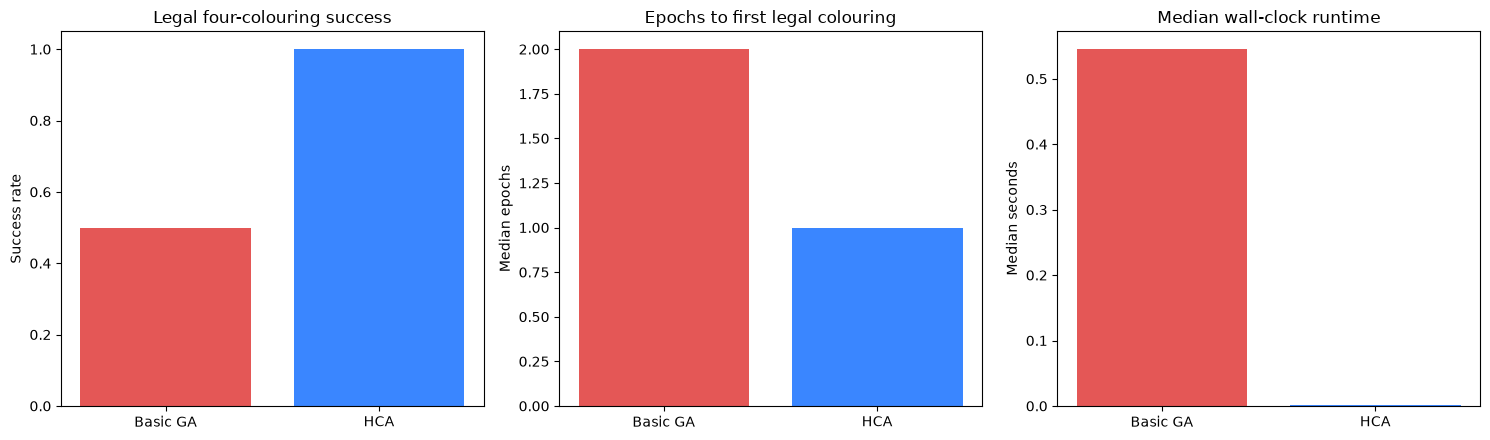

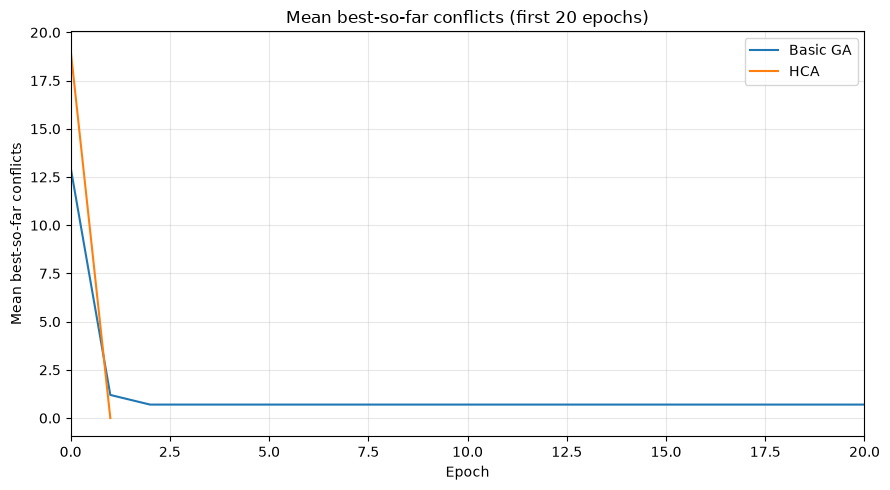

Basic GA: population=120, per-conflicted-country mutation rate=1.0, success=50%, mean conflicts=0.70, median epochs=2, median runtime=0.5453s, median tabu moves=0.0
HCA: population=5, tabu budget=50, success=100%, mean conflicts=0.00, median epochs=1.0, median runtime=0.0007s, median tabu moves=19.5


In [20]:
import matplotlib.pyplot as plt

labels = [summary["algorithm"] for summary in comparison_summary]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].bar(labels, [summary["success_rate"] for summary in comparison_summary], color=["#e45756", "#3a86ff"])
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("Success rate")
axes[0].set_title("Legal four-colouring success")
epoch_values = [
    summary["median_epochs_to_solve"] if math.isfinite(summary["median_epochs_to_solve"]) else 0
    for summary in comparison_summary
]
axes[1].bar(labels, epoch_values, color=["#e45756", "#3a86ff"])
for index, summary in enumerate(comparison_summary):
    if not math.isfinite(summary["median_epochs_to_solve"]):
        axes[1].text(index, 0, "no successes", ha="center", va="bottom", rotation=90)
axes[1].set_ylabel("Median epochs")
axes[1].set_title("Epochs to first legal colouring")
axes[2].bar(labels, [summary["median_runtime_seconds"] for summary in comparison_summary], color=["#e45756", "#3a86ff"])
axes[2].set_ylabel("Median seconds")
axes[2].set_title("Median wall-clock runtime")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
for algorithm in ALGORITHMS:
    records = [record for record in comparison_runs if record["algorithm"] == algorithm]
    longest = max(len(record["history"]) for record in records)
    trajectories = []
    for record in records:
        values = record["history"]
        trajectories.append(values + [values[-1]] * (longest - len(values)))
    average = [mean(values) for values in zip(*trajectories)]
    plt.plot(range(len(average)), average, label=algorithm)
plt.xlabel("Epoch")
plt.ylabel("Mean best-so-far conflicts")
plt.title("Mean best-so-far conflicts (first 20 epochs)")
plt.xlim(0, 20)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

for summary in comparison_summary:
    print(
        f"{summary['algorithm']}: population={summary['population_size']}, "
        f"{summary['parameter_name']}={summary['parameter']}, "
        f"success={summary['success_rate']:.0%}, "
        f"mean conflicts={summary['mean_final_conflicts']:.2f}, "
        f"median epochs={summary['median_epochs_to_solve']}, "
        f"median runtime={summary['median_runtime_seconds']:.4f}s, "
        f"median tabu moves={summary['median_tabu_moves']}"
    )


## 8. Conclusions, limitations, and submission checklist

| Method | Selected settings | Tuning success | Held-out success | Mean held-out conflicts | Median epochs to solution |
|---|---|---:|---:|---:|---:|
| Basic GA | Population 120; per-conflicted-country mutation rate 1.00 | 40% (2/5) | 50% (5/10) | 0.70 | 2 |
| Galinier–Hao HCA | Population 5; tabu budget 50 moves/offspring | 100% (5/5) | 100% (10/10) | 0.00 | 1 |

The basic GA uses two-best selection and conflict-directed valid-colour mutation. HCA uses GPX, tabu-search improvement, and its own parent-replacement strategy, so it is a hybrid evolutionary method rather than a standard GA. On this graph and these fixed seeds HCA solved more runs; the basic GA nevertheless found legal held-out colourings. These small stochastic samples are not definitive estimates of long-run performance. Re-run the notebook before submission if the graph, code, seed set, or parameters change, and update this table from the resulting output.

The basic GA creates a full offspring population each epoch, while HCA includes tabu-search moves. Compare runtime and HCA tabu moves in addition to epochs. The parameter grid and seed counts are modest and do not establish globally optimal settings.
